In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [47]:
bench_data = pd.read_csv("data_extraction/bench_road_enrichment.csv")
plaque_data = pd.read_csv("data_extraction/open-plaques-United-Kingdom-2025-12-14-footway.csv")
monument_data = pd.read_csv("data_extraction/monuments_enriched.csv")
bench_data_inscription = pd.read_csv("bench_data.csv")

In [48]:
hectar_bins = [500, 1000, 5000, 10000, 50000, 100000, 500000, 10000000]


In [49]:
bench_data_inscription['highway'] = bench_data_inscription['bench_id'].apply(lambda x: bench_data[bench_data.feature_id == x]['highway'].values[0])
bench_data_inscription['distance_to_road'] = bench_data_inscription['bench_id'].apply(lambda x: bench_data[bench_data.feature_id == x]['distance_m'].values[0])

In [50]:
bench_data_inscription.to_csv('bench_data_highway.csv')

In [51]:
monument_data = monument_data[monument_data['memorial'] == 'war_memorial']

In [52]:
highway_types = ['motorway', 'trunk', 'primary', 'secondary', 'tertiary', 'residential', 'service', 'footway', 'no roadway']

In [53]:
# limit_distance = 10
# bench_data_inscription[bench_data_inscription.distance_to_road > limit_distance] = np.nan
# bench_data_inscription.loc[bench_data_inscription.distance_to_road.isna(), 'highway'] = 'no roadway'

# monument_data[monument_data.dist > limit_distance] = np.nan
# monument_data.loc[monument_data.dist.isna(), 'highway'] = 'no roadway'

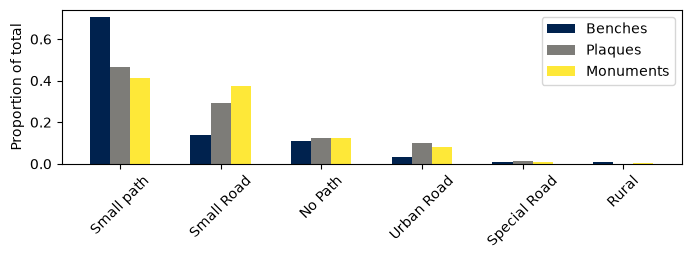

In [54]:
# Use CMU Serif font for this plot
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = ['CMU Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.unicode_minus'] = False

plaques = plaque_data.highway_category.value_counts()
benches = bench_data.highway_category.value_counts()
monuments = monument_data.highway_category.value_counts()

fig,ax = plt.subplots(figsize=(8,2))
# plot benches and plaques on the same axis, bars side by side
# order the bars by highway type

cmap = plt.get_cmap('cividis')
bar_colors = [cmap(i) for i in np.linspace(0, 1, 3)]

# highway_order = [h for h in highway_types if h in benches.index and h in plaques.index and h in monuments.index]
# benches = benches[highway_order]
# plaques = plaques[highway_order]
# monuments = monuments[highway_order]
tot_plaques = plaques.sum()
tot_benches = benches.sum()
tot_monuments = monuments.sum()

pl1 = ax.bar(np.linspace(0, len(benches)-1, len(benches))-0.2, benches.values/tot_benches, width=0.2, label='Benches', align='center', color=bar_colors[0])
pl2 = ax.bar(np.linspace(0, len(plaques)-1, len(plaques)), plaques.values/tot_plaques, width=0.2, label='Plaques', align='center', color=bar_colors[1])
pl3 = ax.bar(np.linspace(0, len(monuments)-1, len(monuments))+0.2, monuments.values/tot_monuments, width=0.2, label='Monuments', align='center', color=bar_colors[2])

ax.set_xticks(np.arange(len(benches)))
ax.set_xticklabels(benches.index, rotation=45)
ax.set_ylabel('Proportion of total')
ax.legend()

In [55]:
bench_file = "data_extraction/data.json"
bench_data_all = pd.read_json(bench_file)

unfound_ids = bench_data[(bench_data.highway.isna()) & (bench_data.is_in_uk == True)]['feature_id']
bench_ids = bench_data_all.features.apply(lambda x: x['id'])


In [56]:
bench_data_all[bench_ids.isin(unfound_ids)]['features'].apply(lambda x: x["properties"]['popupContent'])

151      Who Dares Wins\r\nIn Memory Of\r\nOur Friend\r...
192      In memory of William Kemp died Oct 26th 1977 a...
193      In loving memory of my mum and dad, Betty and ...
196                        In Loving Memory of Ray Hollins
197              John Aveston scientist & sailor 1934-1999
                               ...                        
39853    IN MEMORY OF\r\nFR. PAT MOORE\r\n10TH JUNE 195...
39854    In memory of\r\nGeraldine Singleton Chalk\r\n1...
39862    Susan Findling Fleig\r\n1941-2003\r\nBeloved M...
39864    In loving memory of Lee Zimmerman\r\nB.A.Y.S.I...
39868    IN MEMORY OF SYDNEY JANE REID\r\n26-09-97 - 30...
Name: features, Length: 9528, dtype: str

In [57]:
import requests

link = "https://dev.datacultureportal.uk/wp-json/dataculture-dataset/v1/items?search=poetry"
headers = {
    "User-Agent": "Mozilla/5.0"
}

response = requests.get(link, headers=headers, timeout=30)
print(response.status_code)
print(response.text[:500])

406
<head><title>Not Acceptable!</title></head><body><h1>Not Acceptable!</h1><p>An appropriate representation of the requested resource could not be found on this server. This error was generated by Mod_Security.</p></body></html>


### Highway by built-up-area size

Area bins use `areahectares` (including a `<500 ha` bin). `Not in settlement` identifies rows whose `city` value says `no settlement`. Rows without a mapped area are omitted from plotted cells, but the denominator remains the full row count. Missing highway categories are shown as `Unmapped / missing`. Every cell is the percentage of all rows in that dataset.


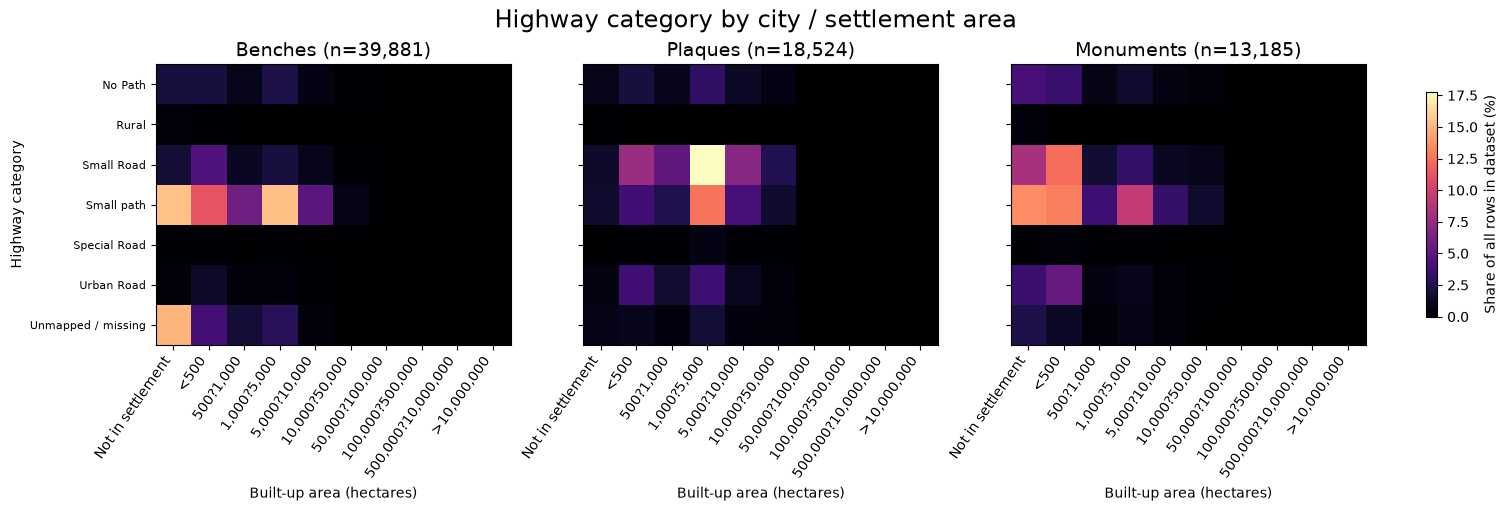

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

hectar_bins = [500, 1000, 5000, 10000, 50000, 100000, 500000, 10000000]
size_labels = [
    "Not in settlement", "<500", "500-1k", "1k-5k",
    "5k-10k", "10k-50k", "50k-100k",
    "100k-500k", "500k-1M", ">1M",
]
unknown_category = "Unmapped / missing"
file_paths = {
    "Benches": Path("data_extraction/bench_road_enrichment.csv"),
    "Plaques": Path("data_extraction/open-plaques-United-Kingdom-2025-12-14-footway.csv"),
    "Monuments": Path("data_extraction/monuments_enriched.csv"),
}

def clean_category(value):
    if pd.isna(value) or str(value).strip().casefold() in {"", "nan", "none", "null"}:
        return unknown_category
    value = str(value).strip()
    return value

plot_data = {}
all_categories = set()
for label, path in file_paths.items():
    frame = pd.read_csv(path)
    if "city" not in frame:
        frame["city"] = ""
    area = pd.to_numeric(frame.get("areahectares", pd.Series(index=frame.index, dtype=float)), errors="coerce")
    frame["_highway_category"] = frame.get("highway_category", pd.Series(index=frame.index, dtype=object)) .map(clean_category)
    city = frame["city"].fillna("").astype(str).str.strip().str.casefold()
    not_in_settlement = city.eq("no settlement")
    valid_area = area.notna() & area.ge(0)
    binned_area = pd.cut(
        area,
        bins=[0, *hectar_bins, np.inf],
        labels=size_labels[1:],
        right=True,
        include_lowest=True,
    )
    frame["_size_bin"] = pd.Series(index=frame.index, dtype="object")
    frame.loc[valid_area, "_size_bin"] = binned_area.loc[valid_area].astype(str)
    frame.loc[not_in_settlement, "_size_bin"] = "Not in settlement"
    plot_data[label] = frame
    all_categories.update(frame["_highway_category"].dropna().unique())

category_labels = sorted(all_categories - {unknown_category}) + [unknown_category]
matrices = {}
for label, frame in plot_data.items():
    counts = pd.crosstab(frame["_highway_category"], frame["_size_bin"])
    counts = counts.reindex(index=category_labels, columns=size_labels, fill_value=0)
    # Use the full row count, so every dataset is normalized to its own total.
    matrices[label] = counts / len(frame) * 100 if len(frame) else counts.astype(float)

vmax = max(float(matrix.to_numpy().max()) for matrix in matrices.values())
vmax = max(vmax, 1e-9)
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, constrained_layout=True)
images = []
for ax, (label, matrix) in zip(axes, matrices.items()):
    image = ax.imshow(matrix.to_numpy(), aspect="auto", interpolation="nearest", cmap="magma", vmin=0, vmax=vmax)
    images.append(image)
    ax.set_title(f"{label} (n={len(plot_data[label]):,})", fontsize=14)
    ax.set_xticks(np.arange(len(size_labels)), labels=size_labels, rotation=55, ha="right")
    ax.set_xlabel("Built-up area (hectares)")
    ax.set_yticks(np.arange(len(category_labels)), labels=category_labels)
    ax.tick_params(axis="y", labelsize=8)
axes[0].set_ylabel("Highway category")
fig.colorbar(images[0], ax=axes, label="Share of all rows in dataset (%)", shrink=0.8)
fig.suptitle("Highway category by city / settlement area", fontsize=17)
plt.show()


### Bench highway values without a category

This table lists the source `highway` values whose `highway_category` is blank.


In [59]:
import pandas as pd

bench_for_category_check = pd.read_csv("data_extraction/bench_road_enrichment.csv")
unmapped_mask = bench_for_category_check["highway_category"].isna() | bench_for_category_check["highway_category"].astype(str).str.strip().eq("")
unmapped_highway_values = (
    bench_for_category_check.loc[unmapped_mask, "highway"]
    .fillna("")
    .astype(str)
    .str.strip()
    .replace("", "(blank / no highway recorded)")
    .value_counts()
    .rename_axis("Highway value")
    .rename("Rows")
    .reset_index()
)
unmapped_highway_values["Dataset share (%)"] = (100 * unmapped_highway_values["Rows"] / len(bench_for_category_check)).round(2)
unmapped_highway_values


,Highway value,Rows,Dataset share (%)
0,(blank / no highway recorded),9528,23.89
